# 2b — Rolling-origin evaluation

Notebook 02 evaluates every model on a single test period (1 to 13 July 2026, about 12 days). This notebook repeats the evaluation on **four consecutive test windows** with an expanding training window (rolling origin), to check whether the comparison with the persistence baselines, the ranking of the models and the value of the day-ahead forecast hold over time.

**Protocol (same as notebook 02, applied to each fold).** Each fold has an inner training period, a 7-day validation period and a test window (fold 4 uses exactly the validation and test periods of notebook 02). The models are fitted on the inner training period and selected on the validation period with the mean CVRMSE criterion. The selected configuration is refitted on the outer training period (inner training plus validation) and evaluated once on the test window. A 12 h embargo separates training from validation and the outer training period from the test window. Feature and target scalers and the operating-regime clustering (k = 8) are refitted for each fold and stage on its own training data only.

**Scope (reduced budget).** The 14 models of notebook 02 are trained with two feature sets, `+ cluster` (no forecast) and `+ day-ahead forecast`, which gives the model comparison and the forecast ablation. The neural networks are tuned with 10 KerasTuner trials and refitted with 3 seeds (20 trials and 5 seeds in notebook 02).

**Caveats.**
* Fold 4 has the same test period as notebook 02, which has already been inspected. It is not a held-out test.
* Fold 1 has only about 2.5 weeks of training data.
* The folds come from the same greenhouse and season, and their training sets overlap, so they are not independent units for a rank test across folds. The inference below uses Diebold–Mariano tests on the test hours of all folds together.

The functions are in `forecast_utils.py`, which reproduces the code of notebook 02 with the split passed as an argument.

In [1]:
import os
import time
import joblib
import numpy as np
import pandas as pd
from IPython.display import display

import forecast_utils as fu
from greenhouse_dataset import TARGET_COLS, get_splits

pd.set_option("display.width", 160)

# ---- run budget -----------------------------------------------------------------------
SMOKE = os.environ.get("GH_SMOKE", "0") == "1"      # quick end-to-end check, numbers NOT meaningful
BUDGET = (fu.Budget(max_trials=1, max_epochs=2, seeds=(0,), rf_trees=10, hgb_iter=20, lookback_grid=(3,))
          if SMOKE else fu.Budget(max_trials=10, seeds=(0, 1, 2)))
RO_FEATURE_SETS = ["+ cluster", "+ day-ahead forecast"]
FS_MAIN, FS_NOFC = "+ day-ahead forecast", "+ cluster"
N_BOOT = 200 if SMOKE else 2000
DM_LAGS = 24
VB_LAGS = (12, 24, 48)

# ---- folds: start of each test window (the last one is the test period of notebook 02) --
SPLITS_02 = get_splits(root=".")
TEST_STARTS = ["2026-06-09 00:00", "2026-06-16 00:00", "2026-06-23 00:00", str(SPLITS_02["test_start"])]
VAL_STARTS = [None, None, None, str(SPLITS_02["val_start"])]   # fold 4 uses exactly the split of notebook 02

# ---- per-fold cache: a fold is retrained only if its file is missing or was made with other settings
RO_DIR = os.path.join("model data", "rolling_origin_smoke" if SMOKE else "rolling_origin")
RO_RERUN = False            # True retrains every fold even if a valid cache file exists
os.makedirs(RO_DIR, exist_ok=True)
print("budget:", BUDGET) 

note: fc_temp_prevday still missing 364h after the short-gap fill; bridging with an unlimited forward-fill of its own past values (flagged in fc_temp_prevday_stale)
note: fc_hum_prevday still missing 364h after the short-gap fill; bridging with an unlimited forward-fill of its own past values (flagged in fc_hum_prevday_stale)
note: fc_viento_prevday still missing 260h after the short-gap fill; bridging with an unlimited forward-fill of its own past values (flagged in fc_viento_prevday_stale)
budget: Budget(max_trials=10, max_epochs=100, patience=8, seeds=(0, 1, 2), rf_trees=200, hgb_iter=300, lookback_grid=(3, 6, 12, 24), kt_dir='kt_tuning_ro')


c:\Users\psyey\OneDrive\Escritorio\Git_repos\Osiris-Greenhouse-UMU\greenhouse_dataset.py:340: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[name] = df[col].shift(-h)


## 2b.1 — Data and folds

In [2]:
D = fu.load_data(root=".")
folds = fu.make_folds(D, TEST_STARTS, VAL_STARTS)
print(f"modelling rows: {len(D['data'])} | common anchor set (24 h complete history): {len(D['anchors'])}")
display(fu.folds_table(folds))

note: fc_temp_prevday still missing 364h after the short-gap fill; bridging with an unlimited forward-fill of its own past values (flagged in fc_temp_prevday_stale)
note: fc_hum_prevday still missing 364h after the short-gap fill; bridging with an unlimited forward-fill of its own past values (flagged in fc_hum_prevday_stale)
note: fc_viento_prevday still missing 260h after the short-gap fill; bridging with an unlimited forward-fill of its own past values (flagged in fc_viento_prevday_stale)
modelling rows: 1456 | common anchor set (24 h complete history): 1374


,inner train end,validation,test,n inner train,n validation,n outer train,n test,test days
fold 1,2026-06-01 00:00:00,2026-06-01 12:00:00 -> 2026-06-08 12:00:00,2026-06-09 00:00:00 -> 2026-06-16 00:00:00,399,128,535,168,7.0
fold 2,2026-06-08 00:00:00,2026-06-08 12:00:00 -> 2026-06-15 12:00:00,2026-06-16 00:00:00 -> 2026-06-23 00:00:00,523,168,703,168,7.0
fold 3,2026-06-15 00:00:00,2026-06-15 12:00:00 -> 2026-06-22 12:00:00,2026-06-23 00:00:00 -> 2026-07-01 07:00:00,691,168,871,199,8.3
fold 4,2026-06-23 02:00:00,2026-06-23 14:00:00 -> 2026-06-30 19:00:00,2026-07-01 07:00:00 -> 2026-07-13 11:00:00,885,173,1070,292,12.2


## 2b.2 — Training (one cache file per fold)

Each fold trains 14 models × 2 feature sets. A fold whose cache file exists and matches the current settings is loaded instead of retrained, so the run can be interrupted and resumed.

In [3]:
def fold_fingerprint(f):
    return dict(budget=vars(BUDGET), feature_sets=RO_FEATURE_SETS, models=fu.MODEL_ORDER,
                val=(str(f.val_start), str(f.train_end)), test=(str(f.test_start), str(f.test_end)),
                n=(len(f.idx["inner"]), len(f.idx["val"]), len(f.idx["test"])))

RO = {}
for f in folds:
    path = os.path.join(RO_DIR, f"{f.name.replace(' ', '_')}.joblib")
    if not RO_RERUN and os.path.exists(path):
        cached = joblib.load(path)
        if cached["fingerprint"] == fold_fingerprint(f):
            RO[f.name] = cached["res"]
            print(f"[cache] {f.name} loaded from {path}")
            continue
        print(f"[cache] {f.name}: settings changed, retraining")
    t0 = time.time()
    res = fu.FoldRunner(D, f, BUDGET).run(RO_FEATURE_SETS)
    joblib.dump({"fingerprint": fold_fingerprint(f), "res": res}, path, compress=3)
    RO[f.name] = res
    print(f"{f.name} done in {(time.time() - t0) / 60:.1f} min -> {path}")

[cache] fold 1 loaded from model data\rolling_origin\fold_1.joblib
[cache] fold 2 loaded from model data\rolling_origin\fold_2.joblib
[cache] fold 3 loaded from model data\rolling_origin\fold_3.joblib
[cache] fold 4 loaded from model data\rolling_origin\fold_4.joblib


## 2b.3 — Accuracy per fold

For each fold, the reference baseline of each target is the better of persistence and seasonal persistence on that fold's validation period. The relative MAE is the MAE divided by the MAE of the reference on the same test window, averaged over the six targets (1 = reference, lower is better).

In [4]:
FOLDS = [f.name for f in folds]
METHODS = list(fu.BASELINES) + fu.MODEL_ORDER

def fold_errors(res, fs):
    # hourly absolute errors per method on the fold's test window
    y = res["y_test"]
    e = {b: fu.abs_err(res["baselines_test"][b], y) for b in fu.BASELINES}
    e.update({m: fu.abs_err(res["pred"][(m, fs)], y) for m in fu.MODEL_ORDER})
    return e

ERR = {fn: fold_errors(RO[fn], FS_MAIN) for fn in FOLDS}
REF_MAE = {}
for fn in FOLDS:
    rc = RO[fn]["ref_choice"]
    REF_MAE[fn] = pd.Series({c: ERR[fn][rc[c]][c].mean() for c in TARGET_COLS})

print("Reference baseline per fold and target (chosen on each fold's validation period):")
display(pd.DataFrame({fn: RO[fn]["ref_choice"] for fn in FOLDS}))

rel = pd.DataFrame({fn: {m: (ERR[fn][m].mean() / REF_MAE[fn]).mean() for m in METHODS} for fn in FOLDS})
rel["mean over folds"] = rel.mean(axis=1)
print(f"Relative MAE ({FS_MAIN}), mean over the six targets:")
display(rel.loc[METHODS].round(3))

for kind, cols, unit in (("temperature", fu.TEMP_TARGET_COLS, "degC"), ("humidity", fu.HUM_TARGET_COLS, "%RH")):
    t = pd.DataFrame({fn: {m: ERR[fn][m][cols].mean().mean() for m in METHODS} for fn in FOLDS})
    t["mean over folds"] = t.mean(axis=1)
    print(f"Test MAE, {kind} ({unit}), mean over the three horizons:")
    display(t.loc[METHODS].round(3))

Reference baseline per fold and target (chosen on each fold's validation period):


,fold 1,fold 2,fold 3,fold 4
temp_h1,persistence,persistence,persistence,seasonal persistence
hum_h1,persistence,persistence,persistence,persistence
temp_h6,seasonal persistence,seasonal persistence,seasonal persistence,seasonal persistence
hum_h6,seasonal persistence,seasonal persistence,seasonal persistence,seasonal persistence
temp_h12,seasonal persistence,seasonal persistence,seasonal persistence,seasonal persistence
hum_h12,seasonal persistence,seasonal persistence,seasonal persistence,seasonal persistence


Relative MAE (+ day-ahead forecast), mean over the six targets:


,fold 1,fold 2,fold 3,fold 4,mean over folds
persistence,2.430,3.017,3.201,3.142,2.948
seasonal persistence,1.230,1.131,1.153,1.149,1.166
Ridge,1.046,1.204,0.996,0.859,1.026
RandomForest,0.850,1.197,1.228,1.167,1.110
HistGB,0.746,0.805,0.992,0.803,0.836
LSTM (t only),2.315,1.198,1.160,0.933,1.402
GRU (t only),2.573,1.365,1.280,1.064,1.570
Attention (t only),2.396,1.151,1.117,1.128,1.448
MLP (t only),32.264,1.339,1.317,0.847,8.942
Ridge (hist),1.094,1.167,0.956,0.789,1.001


Test MAE, temperature (degC), mean over the three horizons:


,fold 1,fold 2,fold 3,fold 4,mean over folds
persistence,4.461,4.680,4.682,5.319,4.785
seasonal persistence,1.558,1.117,0.978,1.132,1.196
Ridge,1.587,1.361,0.924,0.966,1.209
RandomForest,1.203,1.365,1.078,1.618,1.316
HistGB,1.016,0.882,0.734,1.007,0.910
LSTM (t only),3.574,1.433,0.932,1.231,1.792
GRU (t only),3.895,1.772,1.206,1.480,2.088
Attention (t only),3.199,1.373,1.120,1.556,1.812
MLP (t only),55.213,1.795,1.195,1.012,14.804
Ridge (hist),1.466,1.260,0.948,0.824,1.125


Test MAE, humidity (%RH), mean over the three horizons:


,fold 1,fold 2,fold 3,fold 4,mean over folds
persistence,9.847,8.046,8.836,7.880,8.652
seasonal persistence,5.763,5.035,5.971,5.398,5.542
Ridge,4.740,4.955,5.430,4.012,4.784
RandomForest,3.909,4.874,6.471,3.948,4.801
HistGB,3.648,3.454,6.205,3.220,4.131
LSTM (t only),8.814,4.618,6.776,3.525,5.933
GRU (t only),10.543,4.674,6.363,3.640,6.305
Attention (t only),10.868,4.480,5.300,3.892,6.135
MLP (t only),98.616,4.264,6.755,3.538,28.293
Ridge (hist),5.654,5.020,4.791,3.915,4.845


## 2b.4 — Model selected on validation in each fold

The configuration with the lowest validation mean CVRMSE over all models and both feature sets, as in notebook 02.

In [5]:
sel_rows = {}
for fn in FOLDS:
    vc = pd.Series(RO[fn]["val_crit"])
    k = vc.idxmin()
    sel_rows[fn] = {"model": k[0], "feature set": k[1], "val mean CVRMSE": vc[k],
                    "test relative MAE": (fu.abs_err(RO[fn]["pred"][k], RO[fn]["y_test"]).mean() / REF_MAE[fn]).mean(),
                    "rank on test (of 14 models)": int(rel.loc[fu.MODEL_ORDER, fn].rank().get(k[0], np.nan))
                    if k[1] == FS_MAIN else np.nan}
display(pd.DataFrame(sel_rows).T)

,model,feature set,val mean CVRMSE,test relative MAE,rank on test (of 14 models)
fold 1,Ridge,+ day-ahead forecast,0.07794,1.045905,5
fold 2,HistGB (hist),+ day-ahead forecast,0.057242,0.820636,2
fold 3,HistGB (hist),+ day-ahead forecast,0.057514,0.987862,2
fold 4,Ridge,+ day-ahead forecast,0.059543,0.859029,4


## 2b.5 — Every model against both persistence baselines, test hours of all folds together

The hourly losses of the four test windows are concatenated (about 33 days instead of 12) and compared with Diebold–Mariano tests, as in section 2.17b of notebook 02. For the pooled score, the loss of each hour is the mean over the six targets of the absolute error divided by the reference MAE of that target in that fold. Holm is applied over the 28 tests (14 models × 2 baselines) of each scope, separately for each HAC bandwidth L.

In [6]:
def concat_losses(err_by_fold, target=None):
    parts = []
    for fn in FOLDS:
        e = err_by_fold[fn]
        if target is None:
            parts.append(pd.DataFrame({m: (e[m][TARGET_COLS] / REF_MAE[fn]).mean(axis=1) for m in METHODS}))
        else:
            parts.append(pd.DataFrame({m: e[m][target] for m in METHODS}))
    return pd.concat(parts).sort_index()

vb_ro = {"pooled": fu.vs_baselines(concat_losses(ERR), max(fu.HORIZONS), fu.MODEL_ORDER, lags=VB_LAGS)}
for c in TARGET_COLS:
    vb_ro[c] = fu.vs_baselines(concat_losses(ERR, c), fu.horizon_of(c), fu.MODEL_ORDER, lags=VB_LAGS)
vb_ro_long = pd.concat([t.assign(scope=s) for s, t in vb_ro.items()], ignore_index=True)
os.makedirs(os.path.join("paper", "tables"), exist_ok=True)
vb_ro_long.to_csv(os.path.join("paper", "tables", "rolling_origin_models_vs_persistence.csv"), index=False)

n_hours = len(concat_losses(ERR))
print(f"{n_hours} test hours over {len(FOLDS)} folds. diff = MAE(model) - MAE(baseline), negative = model better.")
for scope in ["pooled"] + TARGET_COLS:
    t = vb_ro[scope]
    view = {}
    for b, tag in zip(fu.BASELINES, ("P", "S")):
        s = t[t.baseline == b].set_index("model")
        view[(tag, "diff")] = s["diff"].round(3)
        view[(tag, "rel %")] = s["rel diff (%)"].round(1)
        view[(tag, "p Holm L=24")] = s["p Holm (L=24)"].round(3)
        view[(tag, "verdict")] = s["verdict"]
    print(f"\n== {scope}")
    display(pd.DataFrame(view).reindex(fu.MODEL_ORDER))

print("\nNumber of models per verdict, by scope and baseline (all folds together):")
display(vb_ro_long.groupby(["scope", "baseline"])["verdict"].value_counts().unstack(fill_value=0)
        .reindex(["pooled"] + TARGET_COLS, level=0))

827 test hours over 4 folds. diff = MAE(model) - MAE(baseline), negative = model better.

== pooled


P                                         S                                    
                      diff  rel % p Holm L=24         verdict   diff  rel % p Holm L=24          verdict
model                                                                                                   
Ridge               -1.986  -66.5       0.000  better (all L) -0.163  -14.0       0.379             n.s.
RandomForest        -1.863  -62.4       0.000  better (all L) -0.040   -3.4       1.000             n.s.
HistGB              -2.149  -72.0       0.000  better (all L) -0.326  -28.0       0.000   better (all L)
LSTM (t only)       -1.664  -55.7       0.000  better (all L)  0.159   13.7       0.960             n.s.
GRU (t only)        -1.503  -50.3       0.000  better (all L)  0.320   27.5       0.347             n.s.
Attention (t only)  -1.599  -53.5       0.000  better (all L)  0.225   19.3       0.594             n.s.
MLP (t only)         4.456  149.2       0.633            n.s.  6.279  539.9       0.253   worse (some L)
Ridge (hist)        -2.019  -67.6       0.000  better (all L) -0.195  -16.8       0.208  better (some L)
RandomForest (hist) -1.860  -62.3       0.000  better (all L) -0.037   -3.2       1.000             n.s.
HistGB (hist)       -2.116  -70.9       0.000  better (all L) -0.293  -25.2       0.003   better (all L)
LSTM                -1.571  -52.6       0.000  better (all L)  0.252   21.7       0.371             n.s.
GRU                 -1.606  -53.8       0.000  better (all L)  0.217   18.7       0.650             n.s.
Attention           -1.534  -51.4       0.000  better (all L)  0.289   24.8       0.371             n.s.
MLP                 -0.492  -16.5       1.000            n.s.  1.331  114.4       0.176   worse (some L)


== temp_h1


P                                           S                                    
                       diff   rel % p Holm L=24         verdict    diff   rel % p Holm L=24         verdict
model                                                                                                      
Ridge                -0.338   -31.4       0.000  better (all L)  -0.440   -37.4       0.000  better (all L)
RandomForest          0.024     2.2       1.000            n.s.  -0.078    -6.6       1.000            n.s.
HistGB               -0.431   -40.0       0.000  better (all L)  -0.533   -45.2       0.000  better (all L)
LSTM (t only)         0.260    24.1       1.000            n.s.   0.158    13.4       1.000            n.s.
GRU (t only)          0.469    43.6       0.167  worse (some L)   0.366    31.1       0.452            n.s.
Attention (t only)    0.389    36.1       0.296  worse (some L)   0.287    24.3       0.712            n.s.
MLP (t only)         12.217  1135.5       0.296  worse (some L)  12.114  1028.4       0.296  worse (some L)
Ridge (hist)         -0.357   -33.2       0.000  better (all L)  -0.459   -39.0       0.000  better (all L)
RandomForest (hist)   0.080     7.4       1.000            n.s.  -0.022    -1.9       1.000            n.s.
HistGB (hist)        -0.345   -32.1       0.000  better (all L)  -0.447   -38.0       0.001  better (all L)
LSTM                  0.533    49.5       0.117  worse (some L)   0.430    36.5       0.362            n.s.
GRU                   0.429    39.9       0.296  worse (some L)   0.327    27.7       0.712            n.s.
Attention             0.351    32.6       0.494            n.s.   0.249    21.1       1.000            n.s.
MLP                   2.831   263.2       0.187  worse (some L)   2.729   231.7       0.200  worse (some L)


== hum_h1


P                                          S                                   
                       diff  rel % p Holm L=24         verdict    diff  rel % p Holm L=24         verdict
model                                                                                                    
Ridge                -0.240   -8.0       1.000            n.s.  -2.822  -50.4       0.000  better (all L)
RandomForest          0.721   23.9       0.103  worse (some L)  -1.860  -33.3       0.003  better (all L)
HistGB               -0.281   -9.3       0.995            n.s.  -2.862  -51.2       0.000  better (all L)
LSTM (t only)         1.508   50.1       0.103  worse (some L)  -1.073  -19.2       1.000            n.s.
GRU (t only)          1.918   63.7       0.009  worse (some L)  -0.664  -11.9       1.000            n.s.
Attention (t only)    1.818   60.3       0.047  worse (some L)  -0.764  -13.7       1.000            n.s.
MLP (t only)         21.031  698.1       0.185  worse (some L)  18.449  329.8       0.382            n.s.
Ridge (hist)         -0.119   -4.0       1.000            n.s.  -2.701  -48.3       0.000  better (all L)
RandomForest (hist)   0.916   30.4       0.013  worse (some L)  -1.666  -29.8       0.012  better (all L)
HistGB (hist)        -0.251   -8.3       1.000            n.s.  -2.833  -50.6       0.000  better (all L)
LSTM                  1.718   57.0       0.000   worse (all L)  -0.864  -15.4       1.000            n.s.
GRU                   1.456   48.3       0.075  worse (some L)  -1.126  -20.1       1.000            n.s.
Attention             2.304   76.5       0.000   worse (all L)  -0.278   -5.0       1.000            n.s.
MLP                   5.097  169.2       0.047  worse (some L)   2.515   45.0       1.000            n.s.

... (6 outputs left out)


== hum_h12


P                                          S                                   
                       diff  rel % p Holm L=24         verdict    diff  rel % p Holm L=24         verdict
model                                                                                                    
Ridge                -6.775  -55.4         0.0  better (all L)  -0.030   -0.6       1.000            n.s.
RandomForest         -6.935  -56.7         0.0  better (all L)  -0.191   -3.5       1.000            n.s.
HistGB               -7.491  -61.3         0.0  better (all L)  -0.747  -13.6       1.000            n.s.
LSTM (t only)        -5.997  -49.0         0.0  better (all L)   0.748   13.6       1.000            n.s.
GRU (t only)         -6.243  -51.1         0.0  better (all L)   0.502    9.2       1.000            n.s.
Attention (t only)   -6.187  -50.6         0.0  better (all L)   0.557   10.2       1.000            n.s.
MLP (t only)         18.120  148.2         1.0            n.s.  24.864  453.5       0.314  worse (some L)
Ridge (hist)         -6.706  -54.8         0.0  better (all L)   0.038    0.7       1.000            n.s.
RandomForest (hist)  -6.919  -56.6         0.0  better (all L)  -0.174   -3.2       1.000            n.s.
HistGB (hist)        -7.465  -61.1         0.0  better (all L)  -0.721  -13.1       1.000            n.s.
LSTM                 -6.245  -51.1         0.0  better (all L)   0.500    9.1       1.000            n.s.
GRU                  -6.489  -53.1         0.0  better (all L)   0.256    4.7       1.000            n.s.
Attention            -5.460  -44.7         0.0  better (all L)   1.285   23.4       1.000            n.s.
MLP                  -5.473  -44.8         0.0  better (all L)   1.271   23.2       0.635            n.s.


Number of models per verdict, by scope and baseline (all folds together):


verdict                        better (all L)  better (some L)  n.s.  worse (all L)  worse (some L)
scope    baseline                                                                                  
pooled   persistence                       12                0     2              0               0
         seasonal persistence               2                1     9              0               2
temp_h1  persistence                        4                0     4              0               6
         seasonal persistence               4                0     8              0               2
hum_h1   persistence                        0                0     4              2               8
         seasonal persistence               6                0     8              0               0
temp_h6  persistence                       12                1     1              0               0
         seasonal persistence               0                0     6              0               8
hum_h6   persistence                       12                0     2              0               0
         seasonal persistence               0                0    14              0               0
temp_h12 persistence                       13                0     1              0               0
         seasonal persistence               0                0     3              6               5
hum_h12  persistence                       13                0     1              0               0
         seasonal persistence               0                0    13              0               1

### 2b.5b — The same comparison fold by fold

Number of models significantly better than each baseline in each fold (DM, L = 24, Holm over the 28 tests of each fold and target). This shows whether a result found on the pooled test hours appears in every fold or comes from one of them.

In [7]:
per_fold = {}
for fn in FOLDS:
    for c in TARGET_COLS:
        t = fu.vs_baselines(pd.DataFrame({m: ERR[fn][m][c] for m in METHODS}), fu.horizon_of(c), fu.MODEL_ORDER, lags=(DM_LAGS,))
        for b in fu.BASELINES:
            s = t[t.baseline == b]
            per_fold[(c, b, fn)] = int(((s[f"p Holm (L={DM_LAGS})"] < 0.05) & (s["diff"] < 0)).sum())
pf = pd.Series(per_fold).unstack()
pf.index.names = ["target", "baseline"]
display(pf[FOLDS])

fold 1  fold 2  fold 3  fold 4
target   baseline                                            
hum_h1   persistence                1       0       0       1
         seasonal persistence       6       2       0       9
hum_h12  persistence               12       4       5      14
         seasonal persistence       2       0       0       0
hum_h6   persistence                7      14      12      14
         seasonal persistence       4       0       0       0
temp_h1  persistence                2       2       7       6
         seasonal persistence       3       0       3       2
temp_h12 persistence               12      14      14      14
         seasonal persistence       0       0       0       0
temp_h6  persistence                8      14      14      14
         seasonal persistence       0       0       0       0

## 2b.6 — Stability of the model ranking across folds

Models are ranked in each fold by their relative MAE (1 = best). Kendall's W measures the agreement of the four rankings (1 = identical rankings, 0 = no agreement), and the Spearman correlations compare each pair of folds.

In [8]:
ranks = rel.loc[fu.MODEL_ORDER, FOLDS].rank()
ranks["mean rank"] = ranks.mean(axis=1)
display(ranks.sort_values("mean rank").round(1))

m_, n_ = len(FOLDS), len(fu.MODEL_ORDER)
R = ranks[FOLDS].sum(axis=1)
W = 12 * ((R - R.mean()) ** 2).sum() / (m_ ** 2 * (n_ ** 3 - n_))
print(f"Kendall's W over {m_} folds and {n_} models: {W:.2f}")
print("Spearman correlation of the rankings between folds:")
display(ranks[FOLDS].corr(method="spearman").round(2))

,fold 1,fold 2,fold 3,fold 4,mean rank
HistGB,1.0,1.0,3.0,2.0,1.8
HistGB (hist),2.0,2.0,2.0,5.0,2.8
Ridge (hist),6.0,4.0,1.0,1.0,3.0
Ridge,5.0,8.0,4.0,4.0,5.2
LSTM (t only),8.0,7.0,7.0,6.0,7.0
Attention (t only),9.0,3.0,6.0,11.0,7.2
RandomForest (hist),4.0,5.0,9.0,14.0,8.0
RandomForest,3.0,6.0,11.0,13.0,8.2
GRU,10.0,10.0,5.0,8.0,8.2
LSTM,7.0,13.0,8.0,12.0,10.0


Kendall's W over 4 folds and 14 models: 0.60
Spearman correlation of the rankings between folds:


,fold 1,fold 2,fold 3,fold 4
fold 1,1.00,0.76,0.65,0.03
fold 2,0.76,1.00,0.71,0.21
fold 3,0.65,0.71,1.00,0.45
fold 4,0.03,0.21,0.45,1.00


## 2b.7 — Value of the day-ahead forecast for every model

For every model, `+ day-ahead forecast` against `+ cluster` (the same inputs without the forecast), on the test hours of all folds together. `rel (%)` is the change in MAE (negative = the forecast helps), with its block-bootstrap interval and the DM test (L = 24, Holm over the six targets of each model).

In [9]:
ERR_NOFC = {fn: fold_errors(RO[fn], FS_NOFC) for fn in FOLDS}

def concat_model(err_by_fold, m):
    return pd.concat([err_by_fold[fn][m] for fn in FOLDS]).sort_index()

fc_rows, fc_tables = {}, {}
for m in fu.MODEL_ORDER:
    t = fu.paired_rows(concat_model(ERR, m), concat_model(ERR_NOFC, m), L=DM_LAGS, n_boot=N_BOOT)
    fc_tables[m] = t
    fc_rows[m] = {c: f"{t.loc[c, 'rel (%)']:+.1f}{'*' if t.loc[c, 'p Holm'] < 0.05 else ''}" for c in TARGET_COLS}
print("Change in MAE (%) when the day-ahead forecast is added; * = significant (DM, Holm over the six targets):")
display(pd.DataFrame(fc_rows).T.reindex(fu.MODEL_ORDER)[TARGET_COLS])

print("Change in MAE (%) per fold, mean over the six targets:")
display(pd.DataFrame({fn: {m: 100 * ((ERR[fn][m].mean() - ERR_NOFC[fn][m].mean()) / ERR_NOFC[fn][m].mean()).mean()
                           for m in fu.MODEL_ORDER} for fn in FOLDS}).round(1))

pd.concat(fc_tables, names=["model", "target"]).to_csv(os.path.join("paper", "tables", "rolling_origin_forecast_ablation.csv"))
print("saved:", os.path.join("paper", "tables", "rolling_origin_forecast_ablation.csv"))

Change in MAE (%) when the day-ahead forecast is added; * = significant (DM, Holm over the six targets):


,temp_h1,hum_h1,temp_h6,hum_h6,temp_h12,hum_h12
Ridge,+8.6,+4.4,-23.8*,-15.2*,-21.1*,-15.7*
RandomForest,+6.0*,+7.7*,-8.7*,-6.1*,-10.4*,-11.6*
HistGB,-1.1,-3.1,-20.2*,-13.0*,-31.7*,-17.3*
LSTM (t only),-1.2,+8.1,-15.7*,-3.9,-9.0*,-2.9
GRU (t only),-12.5,-4.3,+3.2,+5.2,+0.3,-12.1*
Attention (t only),-7.3,+5.6,-7.2*,-8.6,-15.5*,-9.2*
MLP (t only),+29.7,+19.9,+44.2,-47.0,-8.0*,-22.6
Ridge (hist),-13.7*,-12.6*,-32.4*,-15.4*,-23.5*,-15.9*
RandomForest (hist),-2.9,+0.2,-14.9*,-9.1*,-11.7*,-12.0*
HistGB (hist),+4.5,+1.9,-27.4*,-13.2*,-23.7*,-16.4*


Change in MAE (%) per fold, mean over the six targets:


,fold 1,fold 2,fold 3,fold 4
Ridge,-14.3,4.6,-9.8,-17.1
RandomForest,-2.2,-2.3,-4.0,-4.0
HistGB,-7.4,-20.3,-10.4,-15.6
LSTM (t only),2.0,-9.1,2.7,-15.8
GRU (t only),16.5,-10.9,-3.4,-12.5
Attention (t only),5.8,-14.2,-8.5,-13.2
MLP (t only),4.4,2.1,-11.1,-20.3
Ridge (hist),-5.1,-12.2,-15.0,-29.8
RandomForest (hist),-7.3,-6.5,-6.2,-10.6
HistGB (hist),-7.0,-19.8,-13.6,-9.0


saved: paper\tables\rolling_origin_forecast_ablation.csv


## 2b.8 — Pairwise Diebold–Mariano comparison of all methods, all folds together

The CD-style diagram of notebook 02 (section 2.17), computed on the test hours of the four folds together instead of the test window of fold 4 only. It compares the 16 methods (14 models and the two persistence forecasts) with pairwise DM tests (HAC with `DM_LAGS` lags) and the Holm correction over the 120 pairs.

* **Global diagram**: the loss of each hour is the mean over the six targets (both variables at +1, +6 and +12 h) of the absolute error divided by the MAE of the reference forecast for that target and fold. It is not a +12 h result: h = 12 is only the value used in the Harvey–Leybourne–Newbold correction, the longest horizon, which makes the test slightly conservative.
* **Per-target diagrams**: absolute error of each target divided by the reference MAE of that target and fold, with the horizon of the target in the HLN correction.
* **Axis**: MAE relative to the reference (lower is better). A bar joins methods that are consecutive on the axis and of which no pair differs significantly. The absence of a bar does **not** mean a significant difference.
* **Markers P and S**: test of each method against persistence (P) and seasonal persistence (S): filled circle = significantly better, hollow circle = not distinguishable, red triangle = significantly worse.

The figures are saved in `paper/IEEE_Conference_Template/figures/` (`dm_diagram_rolling_all.pdf` and `dm_diagram_rolling_targets.pdf`).


16 methods, 120 pairs, 827 test hours over 4 folds; 44 pairs significantly different (Holm, alpha = 0.05)
Test of every method against the two persistence forecasts (pooled loss; +1 better, -1 worse, 0 not distinguishable):


,P,S,relative MAE
HistGB,1.0,1.0,0.837
HistGB (hist),1.0,1.0,0.870
Ridge (hist),1.0,0.0,0.968
Ridge,1.0,0.0,1.000
RandomForest,1.0,0.0,1.123
RandomForest (hist),1.0,0.0,1.126
seasonal persistence,1.0,NaN,1.163
LSTM (t only),1.0,0.0,1.322
GRU,1.0,0.0,1.380
Attention (t only),1.0,0.0,1.388


Holm-adjusted DM p-values, all pairs (pooled loss):


,HistGB,HistGB (hist),Ridge (hist),Ridge,RandomForest,RandomForest (hist),seasonal persistence,LSTM (t only),GRU,Attention (t only),LSTM,Attention,GRU (t only),MLP,persistence,MLP (t only)
HistGB,NaN,0.592,0.140,0.004,0.000,0.000,0.002,0.006,0.004,0.001,0.000,0.000,0.000,0.151,0.0,0.751
HistGB (hist),0.592,NaN,0.966,0.247,0.000,0.000,0.019,0.022,0.014,0.002,0.000,0.001,0.001,0.183,0.0,0.752
Ridge (hist),0.140,0.966,NaN,0.966,0.614,0.580,0.752,0.065,0.029,0.008,0.000,0.002,0.002,0.232,0.0,0.769
Ridge,0.004,0.247,0.966,NaN,0.837,0.831,1.000,0.247,0.126,0.044,0.001,0.011,0.011,0.297,0.0,0.787
RandomForest,0.000,0.000,0.614,0.837,NaN,1.000,1.000,1.000,1.000,1.000,0.468,0.831,0.741,0.682,0.0,0.831
RandomForest (hist),0.000,0.000,0.580,0.831,1.000,NaN,1.000,1.000,1.000,1.000,0.468,0.831,0.741,0.682,0.0,0.831
seasonal persistence,0.002,0.019,0.752,1.000,1.000,1.000,NaN,1.000,1.000,1.000,0.964,0.964,0.851,0.682,0.0,0.831
LSTM (t only),0.006,0.022,0.065,0.247,1.000,1.000,1.000,NaN,1.000,0.831,0.831,0.000,0.000,0.326,0.0,0.826
GRU,0.004,0.014,0.029,0.126,1.000,1.000,1.000,1.000,NaN,1.000,1.000,0.151,0.004,0.423,0.0,0.831
Attention (t only),0.001,0.002,0.008,0.044,1.000,1.000,1.000,0.831,1.000,NaN,1.000,0.169,0.309,0.519,0.0,0.831


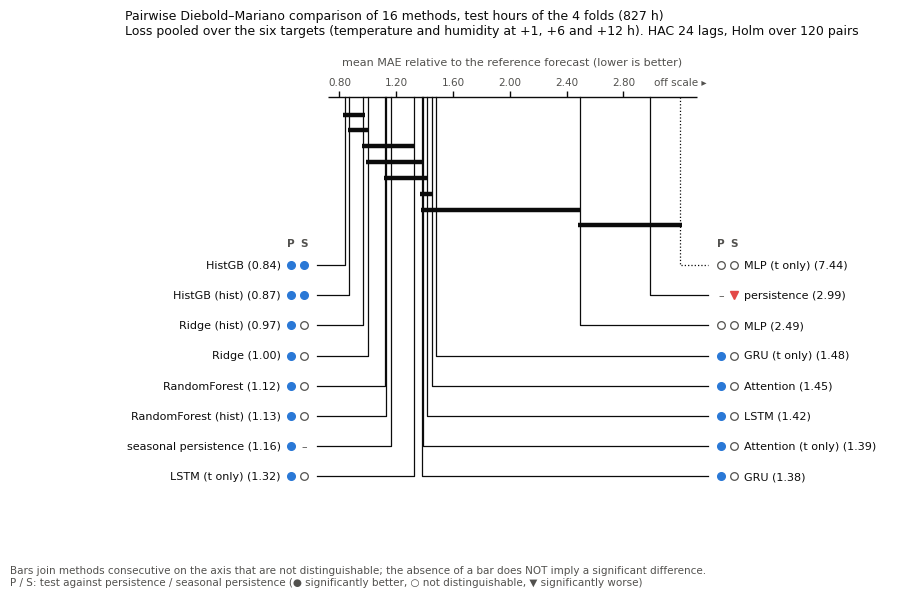

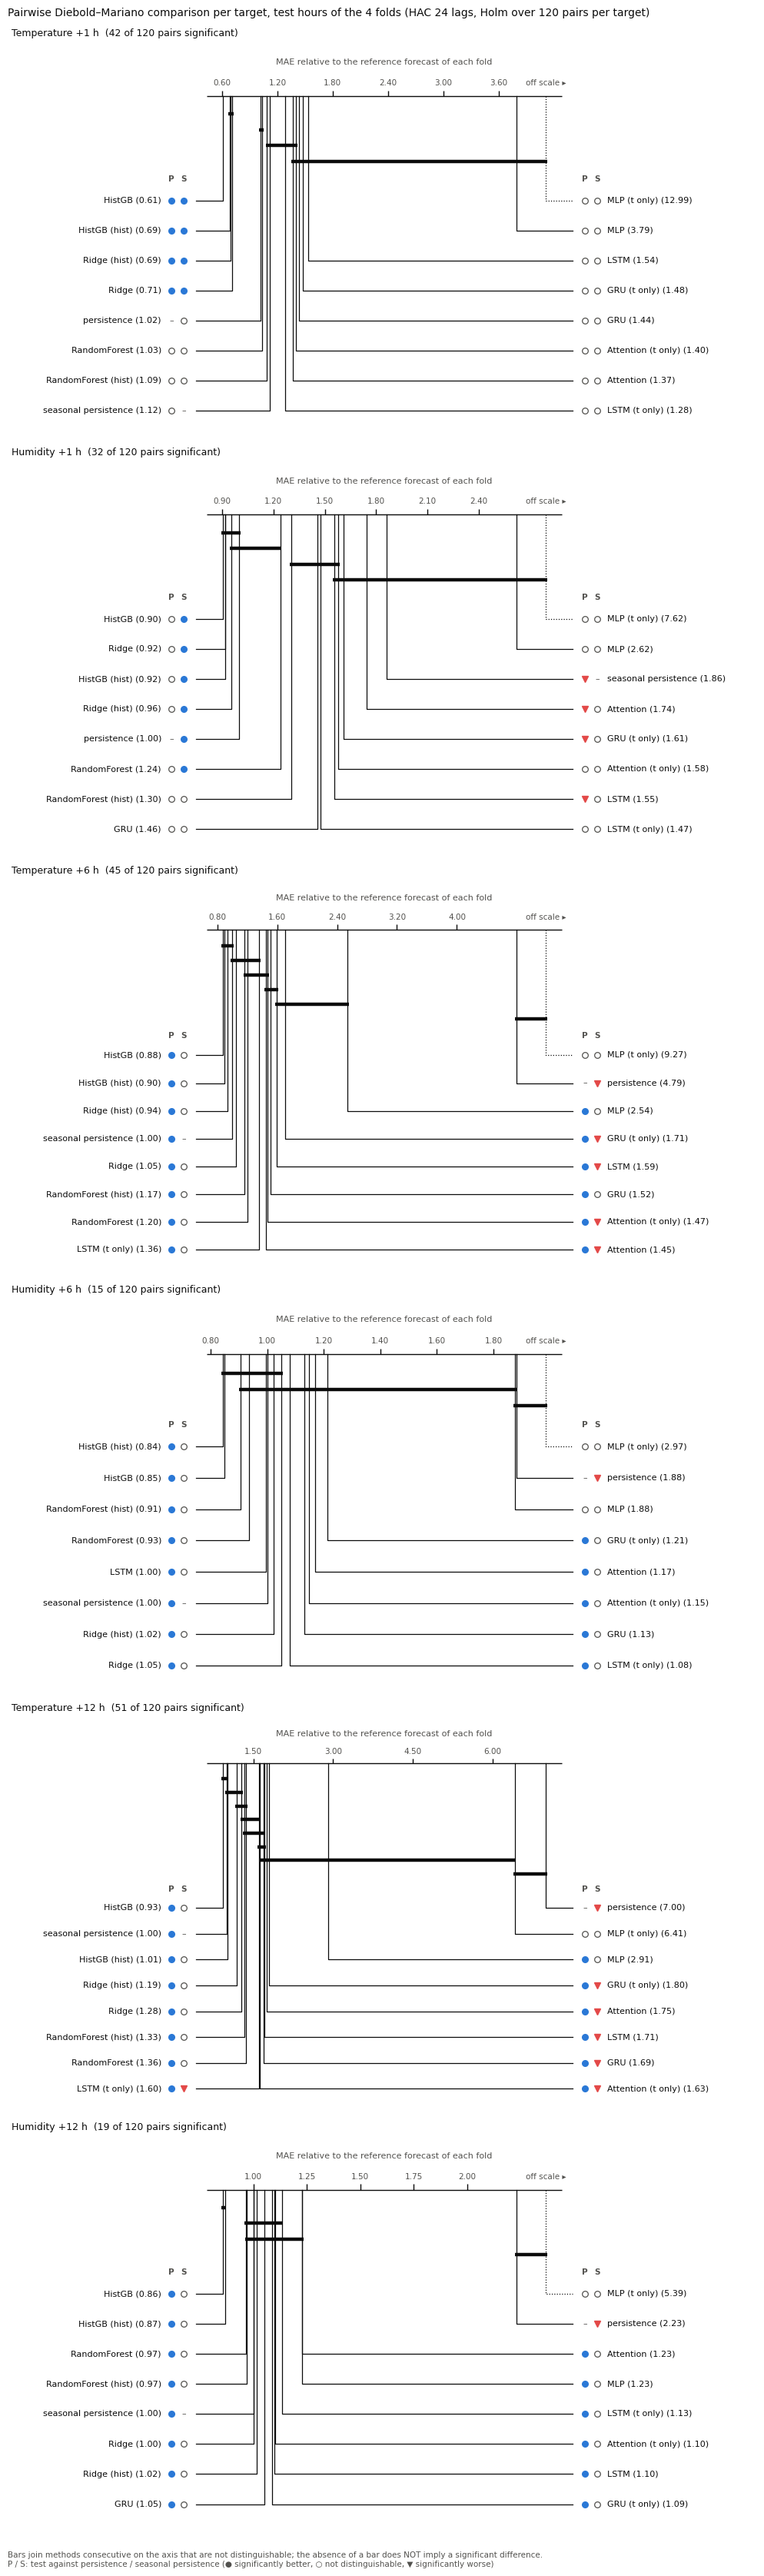

Methods significantly better than each persistence forecast, per target:


,P,S
temp_h1,"Ridge, HistGB, Ridge (hist), HistGB (hist)","Ridge, HistGB, Ridge (hist), HistGB (hist)"
hum_h1,none,"persistence, Ridge, RandomForest, HistGB, Ridg..."
temp_h6,"seasonal persistence, Ridge, RandomForest, His...",none
hum_h6,"seasonal persistence, Ridge, RandomForest, His...",none
temp_h12,"seasonal persistence, Ridge, RandomForest, His...",none
hum_h12,"seasonal persistence, Ridge, RandomForest, His...",none


saved: paper\IEEE_Conference_Template\figures\dm_diagram_rolling_all.pdf and paper\IEEE_Conference_Template\figures\dm_diagram_rolling_targets.pdf


In [10]:
import matplotlib.pyplot as plt

FIG_DIR = os.path.join("paper", "IEEE_Conference_Template", "figures")
os.makedirs(FIG_DIR, exist_ok=True)
TARGET_LABEL = {c: f"{'Temperature' if c.startswith('temp') else 'Humidity'} +{fu.horizon_of(c)} h" for c in TARGET_COLS}

# ---- global diagram: pooled loss over the six targets, test hours of the four folds -------
loss_all_ro = concat_losses(ERR)
pw_all_ro = fu.dm_pairwise(loss_all_ro, h=max(fu.HORIZONS), L=DM_LAGS)
score_all_ro = loss_all_ro.mean()
order_all_ro = list(score_all_ro.sort_values().index)
print(f"{len(METHODS)} methods, {len(pw_all_ro)} pairs, {len(loss_all_ro)} test hours over {len(FOLDS)} folds; "
      f"{int(pw_all_ro['significant'].sum())} pairs significantly different (Holm, alpha = 0.05)")
print("Test of every method against the two persistence forecasts (pooled loss; +1 better, -1 worse, 0 not distinguishable):")
display(pd.DataFrame({tag: fu.baseline_status(pw_all_ro, base) for base, tag in fu.BASELINE_TAGS})
        .reindex(order_all_ro).assign(**{"relative MAE": score_all_ro.round(3)}))
print("Holm-adjusted DM p-values, all pairs (pooled loss):")
display(fu.dm_matrix(pw_all_ro, order_all_ro).round(3))

fig, ax = plt.subplots(figsize=(10, 0.42 * int(np.ceil(len(METHODS) / 2)) + 2.6))
fu.draw_dm_diagram(score_all_ro, pw_all_ro,
                   f"Pairwise Diebold–Mariano comparison of {len(METHODS)} methods, test hours of the {len(FOLDS)} folds "
                   f"({len(loss_all_ro)} h)\nLoss pooled over the six targets (temperature and humidity at +1, +6 and +12 h). "
                   f"HAC {DM_LAGS} lags, Holm over {len(pw_all_ro)} pairs",
                   ax, "mean MAE relative to the reference forecast (lower is better)")
fig.text(0.01, -0.03, fu.DMD_KEY, fontsize=7.5, color=fu.INK2)
fig.savefig(os.path.join(FIG_DIR, "dm_diagram_rolling_all.pdf"), bbox_inches="tight")
plt.show()

# ---- one diagram per target ---------------------------------------------------------------
def concat_rel(target):
    return pd.concat([pd.DataFrame({m: ERR[fn][m][target] / REF_MAE[fn][target] for m in METHODS})
                      for fn in FOLDS]).sort_index()

dmd_ro_target = {}
fig, axes = plt.subplots(len(TARGET_COLS), 1, figsize=(10, len(TARGET_COLS) * (0.42 * int(np.ceil(len(METHODS) / 2)) + 2.3)))
for ax, c in zip(axes, TARGET_COLS):
    loss_c = concat_rel(c)
    pw_c = fu.dm_pairwise(loss_c, h=fu.horizon_of(c), L=DM_LAGS)
    dmd_ro_target[c] = dict(score=loss_c.mean(), pairwise=pw_c)
    fu.draw_dm_diagram(loss_c.mean(), pw_c,
                       f"{TARGET_LABEL[c]}  ({int(pw_c['significant'].sum())} of {len(pw_c)} pairs significant)",
                       ax, "MAE relative to the reference forecast of each fold")
fig.suptitle(f"Pairwise Diebold–Mariano comparison per target, test hours of the {len(FOLDS)} folds "
             f"(HAC {DM_LAGS} lags, Holm over {len(pw_all_ro)} pairs per target)",
             x=0.01, ha="left", fontsize=10, color=fu.INK)
fig.text(0.01, 0.0, fu.DMD_KEY, fontsize=7.5, color=fu.INK2)
plt.tight_layout(rect=(0, 0.01, 1, 0.985))
fig.savefig(os.path.join(FIG_DIR, "dm_diagram_rolling_targets.pdf"), bbox_inches="tight")
plt.show()

print("Methods significantly better than each persistence forecast, per target:")
display(pd.DataFrame({c: {tag: ", ".join(m for m, s in fu.baseline_status(d["pairwise"], base).items() if s == 1) or "none"
                          for base, tag in fu.BASELINE_TAGS} for c, d in dmd_ro_target.items()}).T)
print("saved:", os.path.join(FIG_DIR, "dm_diagram_rolling_all.pdf"), "and", os.path.join(FIG_DIR, "dm_diagram_rolling_targets.pdf"))
